In [ ]:
import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
(ds_train, ds_test), info = tfds.load(
    "cats_vs_dogs",
    split=["train[:80%]", "train[80%:]"],
    as_supervised=True,
    with_info=True
)

print(info)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cats_vs_dogs/incomplete.22CTRW_4.0.1/cats_vs_dogs-train.tfrecord-[0-9][0-9…

Dataset cats_vs_dogs downloaded and prepared to /root/tensorflow_datasets/cats_vs_dogs/4.0.1. Subsequent calls will reuse this data.
tfds.core.DatasetInfo(
    name='cats_vs_dogs',
    full_name='cats_vs_dogs/4.0.1',
    description="""
    A large set of images of cats and dogs. There are 1738 corrupted images that are dropped.
    """,
    homepage='https://www.microsoft.com/en-us/download/details.aspx?id=54765',
    data_dir='/root/tensorflow_datasets/cats_vs_dogs/4.0.1',
    file_format=tfrecord,
    download_size=786.67 MiB,
    dataset_size=1.04 GiB,
    features=FeaturesDict({
        'image': Image(shape=(None, None, 3), dtype=uint8),
        'image/filename': Text(shape=(), dtype=string),
        'label': ClassLabel(shape=(), dtype=int64, num_classes=2),
    }),
    supervised_keys=('image', 'label'),
    disable_shuffling=False,
    nondeterministic_order=False,
    splits={
        'train': <SplitInfo num_examples=23262, num_shards=16>,
    },
    citation="""@Inproceedings 

In [ ]:
(ds_train, ds_val, ds_test), info = tfds.load(
    "cats_vs_dogs",
    split=[
        "train[:80%]",
        "train[80%:90%]",
        "train[90%:]"
    ],
    as_supervised=True,
    with_info=True
)

print("Total Images:", info.splits["train"].num_examples)
print("Classes:", info.features["label"].names)

Total Images: 23262
Classes: ['cat', 'dog']


In [ ]:
IMG_SIZE = 150
BATCH_SIZE = 32

def preprocess_image(image, label):

    # Resize image
    image = tf.image.resize(
        image,
        (IMG_SIZE, IMG_SIZE)
    )

    # Normalize pixel values (0-255 to 0-1)
    image = image / 255.0

    return image, label

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = (
    ds_train
    .shuffle(2000)
    .map(preprocess_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_ds = (
    ds_val
    .map(preprocess_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

test_ds = (
    ds_test
    .map(preprocess_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

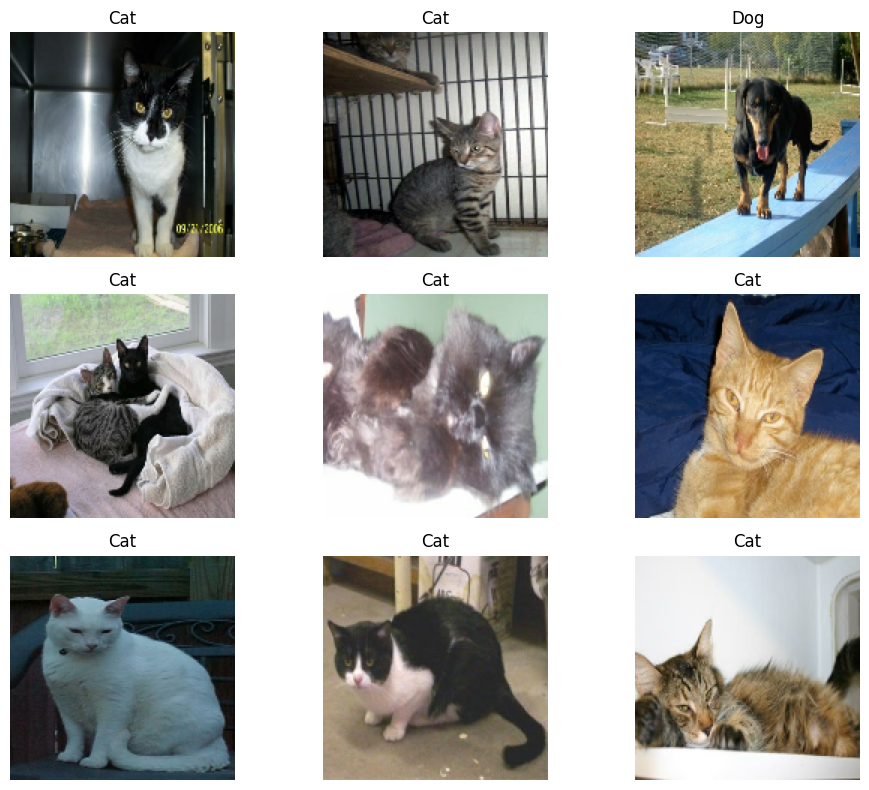

In [ ]:
plt.figure(figsize=(10, 8))

for images, labels in train_ds.take(1):

    for i in range(9):

        plt.subplot(3, 3, i + 1)

        plt.imshow(images[i])

        label = "Dog" if labels[i].numpy() == 1 else "Cat"

        plt.title(label)
        plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
model = models.Sequential([

    # Input layer
    layers.Input(shape=(150, 150, 3)),

    # First convolution block
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Second convolution block
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Third convolution block
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Convert feature maps into 1D
    layers.Flatten(),

    # Fully connected layer
    layers.Dense(128, activation="relu"),

    # Dropout to reduce overfitting
    layers.Dropout(0.5),

    # Binary classification output
    layers.Dense(1, activation="sigmoid")

])

In [ ]:
model.compile(

    optimizer="adam",

    loss="binary_crossentropy",

    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(),
        tf.keras.metrics.Recall()
    ]

)

In [ ]:
history = model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=10

)

Epoch 1/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 888s 2s/step - accuracy: 0.6169 - loss: 0.6552 - precision_1: 0.6199 - recall_1: 0.5887 - val_accuracy: 0.6582 - val_loss: 0.6092 - val_precision_1: 0.7065 - val_recall_1: 0.5829
Epoch 2/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 839s 1s/step - accuracy: 0.7207 - loss: 0.5505 - precision_1: 0.7254 - recall_1: 0.7033 - val_accuracy: 0.7588 - val_loss: 0.5012 - val_precision_1: 0.8241 - val_recall_1: 0.6799
Epoch 3/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 823s 1s/step - accuracy: 0.7921 - loss: 0.4437 - precision_1: 0.7943 - recall_1: 0.7839 - val_accuracy: 0.8104 - val_loss: 0.4187 - val_precision_1: 0.8195 - val_recall_1: 0.8134
Epoch 4/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 827s 1s/step - accuracy: 0.8334 - loss: 0.3790 - precision_1: 0.8327 - recall_1: 0.8312 - val_accuracy: 0.8138 - val_loss: 0.4315 - val_precision_1: 0.7926 - val_recall_1: 0.8682
Epoch 5/10
164/582 ━━━━━━━━━━━━━━━━━━━━ 9:25 1s/step - accuracy: 0.8508 - loss: 0.3515 - precision_1: 0.8527 - recall_1: 0.8

In [ ]:
test_loss, test_accuracy, precision, recall = model.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Precision:", precision)
print("Recall:", recall)

In [ ]:
plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

# Loss
plt.subplot(1, 2, 2)

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
y_true = np.concatenate([
    labels.numpy()
    for _, labels in test_ds
])

y_pred_prob = model.predict(test_ds)

y_pred = (y_pred_prob >= 0.5).astype(int).flatten()

print(
    classification_report(
        y_true,
        y_pred,
        target_names=["Cat", "Dog"]
    )
)

In [ ]:
from tensorflow.keras.utils import load_img, img_to_array

def predict_animal(image_path):

    # Load image
    img = load_img(
        image_path,
        target_size=(150, 150)
    )

    # Convert image into array
    img_array = img_to_array(img)

    # Normalize
    img_array = img_array / 255.0

    # Add batch dimension
    img_array = np.expand_dims(img_array, axis=0)

    # Predict
    probability = model.predict(img_array, verbose=0)[0][0]

    # Classify
    if probability >= 0.5:
        prediction = "Dog"
        confidence = probability
    else:
        prediction = "Cat"
        confidence = 1 - probability

    print("Prediction:", prediction)
    print("Confidence:", round(float(confidence) * 100, 2), "%")

    plt.imshow(img)
    plt.title(prediction)
    plt.axis("off")
    plt.show()

In [ ]:
predict_animal("my_cat.jpg")

In [ ]:
predict_animal("my_dog.jpg")

In [ ]:
model.save("cat_dog_cnn.keras")

In [ ]:
model = tf.keras.models.load_model(
    "cat_dog_cnn.keras"
)